In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [47]:
df = pd.read_csv('electricity_bill.csv')
df.head()

,Units_Consumed,Electricity_Bill
0,152,1010.93
1,485,3861.19
2,398,3210.64
3,320,2678.67
4,156,1239.04


In [48]:
df.shape

(500, 2)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Units_Consumed    500 non-null    int64  
 1   Electricity_Bill  500 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 7.9 KB


In [50]:
df.isnull().sum()

,0
Units_Consumed,0
Electricity_Bill,0


Text(0, 0.5, 'Electricity_Bill')

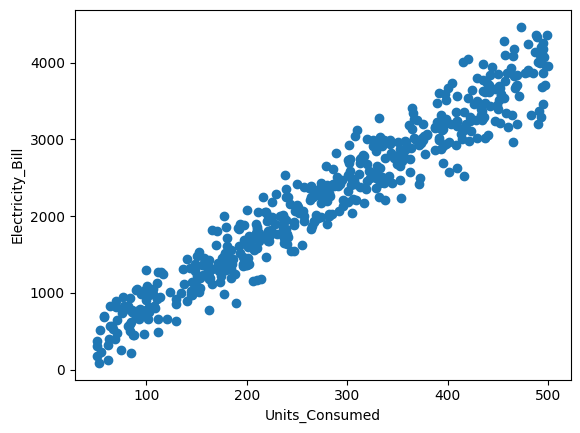

In [51]:
plt.scatter(df['Units_Consumed'], df['Electricity_Bill'])
plt.xlabel('Units_Consumed')
plt.ylabel('Electricity_Bill')

<Axes: ylabel='Units_Consumed'>

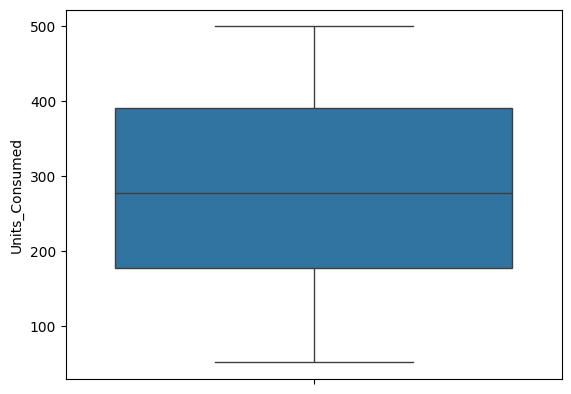

In [52]:
import seaborn as sns
sns.boxplot(df['Units_Consumed'])

<Axes: ylabel='Electricity_Bill'>

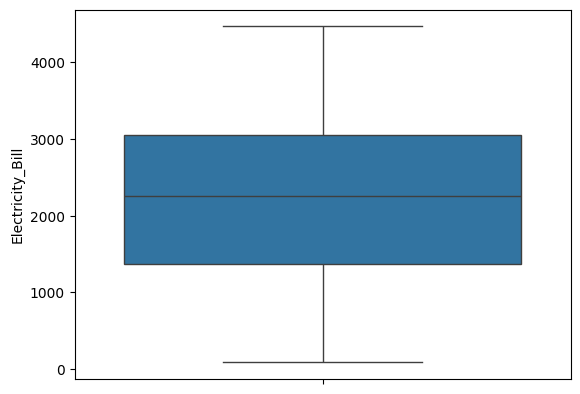

In [53]:
sns.boxplot(df['Electricity_Bill'])

In [54]:
X = df['Units_Consumed'].values
y = df['Electricity_Bill'].values

In [55]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [56]:
X_test

array([243, 130, 433, 306, 102, 332, 244, 130, 477, 499, 171, 111,  53,
       240, 326,  87, 199,  71, 148, 241, 202, 235, 247, 398, 409,  88,
       107, 426, 286, 196,  69, 257, 107, 101, 398, 148,  98, 480, 274,
       435, 424, 353, 337, 209, 394, 437, 152, 380, 422, 463, 255,  78,
       280,  66,  94, 437, 263, 199, 380,  51, 174, 221, 418, 403, 439,
       239, 176, 293, 101, 100, 276, 169, 374, 308, 312, 473, 373, 313,
       153, 404, 180, 309, 313, 290, 161, 495, 192,  95, 483, 421, 225,
       362, 359,  51, 465, 469, 267,  99, 272, 409])

In [57]:
y_test

array([2158.84,  634.39, 3400.93, 2229.05,  769.93, 3283.5 , 1541.86,
        916.7 , 3860.21, 4360.4 , 1383.82,  915.68,   89.18, 1640.11,
       2990.75,  452.26, 1640.91,  481.91, 1052.6 , 1723.36, 1377.17,
       1760.6 , 1551.86, 2939.14, 3238.64,  445.54, 1047.46, 3456.53,
       2424.72, 1350.56,  400.31, 2375.17,  990.37, 1095.84, 3210.64,
       1341.2 ,  719.89, 4243.91, 2172.98, 3635.87, 3648.46, 2870.79,
       2432.19, 1731.05, 3190.88, 3023.84, 1010.93, 3070.55, 3244.63,
       3934.71, 1617.46,  824.21, 2369.28,  562.63,  786.18, 3619.67,
       2203.7 , 1357.04, 3052.86,  304.16, 1217.58, 1710.34, 3201.3 ,
       3194.32, 3738.53, 2250.58, 1375.32, 2423.42, 1029.97,  773.33,
       2319.94, 1626.36, 2947.56, 3040.69, 2550.57, 4466.78, 2493.17,
       2686.71, 1188.81, 3736.72, 1478.78, 2211.92, 2382.79, 2505.07,
       1303.75, 4173.25, 1605.24,  978.9 , 3320.74, 2985.14, 1992.88,
       3188.68, 2960.94,  372.55, 2967.17, 3704.56, 1938.87, 1039.92,
       2352.  , 2627

In [58]:
#Calculation of m(weights) and b(bias)
num = 0
den = 0

for i in range(X_train.shape[0]):
  num = num + (X_train[i] - X_train.mean())*(y_train[i] - y_train.mean())
  den = den + (X_train[i] - X_train.mean())*(X_train[i] - X_train.mean())

m = num/den
b = y_train.mean() - (m * X_train.mean())

print("Slope:", m)
print("Intercept:", b)


Slope: 7.860941211659165
Intercept: 52.40927246319143


In [59]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [60]:
model.fit(X_train.reshape(-1,1), y_train)

LinearRegression()

In [61]:
model.coef_

array([7.86094121])

In [62]:
model.intercept_

np.float64(52.40927246319143)

In [63]:
y_pred = model.predict(X_test.reshape(-1,1))

In [64]:
y_pred

array([1962.6179869 , 1074.33162998, 3456.19681711, 2457.85728323,
        854.22527605, 2662.24175473, 1970.47892811, 1074.33162998,
       3802.07823042, 3975.01893708, 1396.63021966,  924.97374696,
        469.03915668, 1939.03516326, 2615.07610746,  736.31115788,
       1616.73657358,  610.53609849, 1215.82857179, 1946.89610447,
       1640.31939722, 1899.7304572 , 1994.06175174, 3181.0638747 ,
       3267.53422803,  744.17209909,  893.52998211, 3401.17022863,
       2300.638459  , 1593.15374995,  594.81421607, 2072.67116386,
        893.52998211,  846.36433484, 3181.0638747 , 1215.82857179,
        822.78151121, 3825.66105406, 2206.30716446, 3471.91869953,
       3385.44834621, 2827.32152018, 2701.54646079, 1695.3459857 ,
       3149.62010986, 3487.64058196, 1247.27233664, 3039.56693289,
       3369.72646378, 3692.02505346, 2056.94928144,  665.56268697,
       2253.47281173,  571.23139243,  791.33774636, 3487.64058196,
       2119.83681113, 1616.73657358, 3039.56693289,  453.31727

Text(0, 0.5, 'Electricity_Bill')

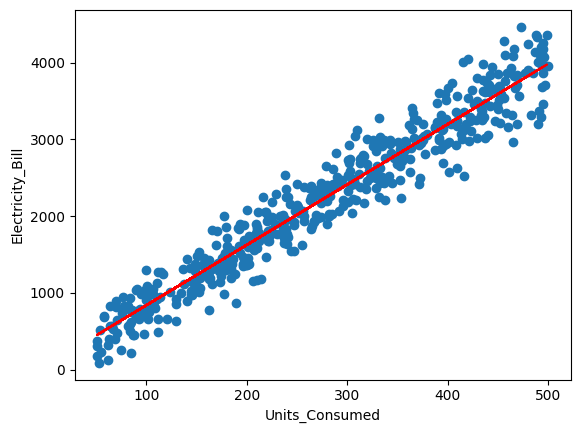

In [65]:
plt.scatter(df['Units_Consumed'], df['Electricity_Bill'])
plt.plot(X_test, y_pred, color='red')
plt.xlabel('Units_Consumed')
plt.ylabel('Electricity_Bill')

In [66]:
y_pred

array([1962.6179869 , 1074.33162998, 3456.19681711, 2457.85728323,
        854.22527605, 2662.24175473, 1970.47892811, 1074.33162998,
       3802.07823042, 3975.01893708, 1396.63021966,  924.97374696,
        469.03915668, 1939.03516326, 2615.07610746,  736.31115788,
       1616.73657358,  610.53609849, 1215.82857179, 1946.89610447,
       1640.31939722, 1899.7304572 , 1994.06175174, 3181.0638747 ,
       3267.53422803,  744.17209909,  893.52998211, 3401.17022863,
       2300.638459  , 1593.15374995,  594.81421607, 2072.67116386,
        893.52998211,  846.36433484, 3181.0638747 , 1215.82857179,
        822.78151121, 3825.66105406, 2206.30716446, 3471.91869953,
       3385.44834621, 2827.32152018, 2701.54646079, 1695.3459857 ,
       3149.62010986, 3487.64058196, 1247.27233664, 3039.56693289,
       3369.72646378, 3692.02505346, 2056.94928144,  665.56268697,
       2253.47281173,  571.23139243,  791.33774636, 3487.64058196,
       2119.83681113, 1616.73657358, 3039.56693289,  453.31727

In [67]:
loss = y_test - y_pred
print("Error: ",loss)

Error:  [ 196.2220131  -439.94162998  -55.26681711 -228.80728323  -84.29527605
  621.25824527 -428.61892811 -157.63162998   58.13176958  385.38106292
  -12.81021966   -9.29374696 -379.85915668 -298.92516326  375.67389254
 -284.05115788   24.17342642 -128.62609849 -163.22857179 -223.53610447
 -263.14939722 -139.1304572  -442.20175174 -241.9238747   -28.89422803
 -298.63209909  153.93001789   55.35977137  124.081541   -242.59374995
 -194.50421607  302.49883614   96.84001789  249.47566516   29.5761253
  125.37142821 -102.89151121  418.24894594  -33.32716446  163.95130047
  263.01165379   43.46847982 -269.35646079   35.7040143    41.25989014
 -463.80058196 -236.34233664   30.98306711 -125.09646378  242.68494654
 -439.48928144  158.64731303  115.80718827   -8.60139243   -5.15774636
  132.02941804   83.86318887 -259.69657358   13.29306711 -149.15727426
 -202.63304329  -79.33728024 -136.98269894  -26.04858076  235.16753562
  319.40577795  -60.61492572   67.75495252  183.60566516  -65.17339363

In [72]:
#Evaluation the metrics
print("Mean Absolute Error: ", np.mean(np.abs(loss)))
print("Mean Squared Error: ", np.mean(loss**2))
print("Root Mean Squared Error: ", np.sqrt(np.mean(loss**2)))
print("R2 score: ", model.score(X_test.reshape(-1,1), y_test))

Mean Absolute Error:  202.77849256810663
Mean Squared Error:  69097.66524541932
Root Mean Squared Error:  262.8643476118801
R2 score:  0.9429718725608217


In [69]:
#Predict the Electricity bill when units_consumed = 300 units
new_df = [[300]]
y_pred = model.predict(new_df)
print(y_pred)

[2410.69163596]
